Final MazE protein count (deterministic): 534.3 copies


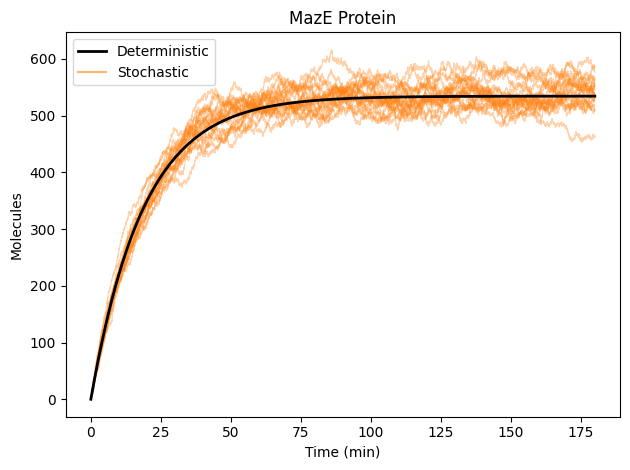

In [1]:
# Code for MazE

import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
k_syn_mazE = 28.32
gamma_maze = 0.053

# ---- Deterministic (Euler) ----
time = 180
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

maze = np.zeros(n_step)

# Run for loop
for i in range(n_step - 1):
  dmaze_dt = k_syn_mazE - gamma_maze*maze[i]

  maze[i+1] = maze[i] + dmaze_dt*delta_t

print(f"Final MazE protein count (deterministic): {np.round(maze[n_step-1],2)} copies")

# ---- Stochastic (Gillespie) ----
def gillespie(maze_prot=0, max_step=500000, t_stop=time):
  t = 0
  prot_maze = maze_prot

  t_vals   = [t]
  prot_vals = [prot_maze]

  for step in range(max_step):
    a1 = k_syn_mazE
    a2 = gamma_maze*prot_maze
    a  = [a1, a2]
    a0 = np.sum(a)

    if a0 == 0:
      break

    r1 = np.random.rand()
    r2 = np.random.rand()
    tau = -np.log(r1)/a0
    t += tau
    if t > t_stop:
      break
    t_vals.append(t)

    r_mod = r2*a0
    next_reaction_idx = -1
    cumulative_rate = 0
    for i, ai in enumerate(a):
      cumulative_rate += ai
      if r_mod < cumulative_rate:
        next_reaction_idx = i
        break

    if next_reaction_idx == 0:
      prot_maze += 1
    elif next_reaction_idx == 1:
      prot_maze -= 1


    prot_maze = max(prot_maze, 0)
    prot_vals.append(prot_maze)

  return t_vals, prot_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20

for i in range(runs):
  t_vals, prot_vals = gillespie()
  plt.plot(t_vals, prot_vals, color='tab:orange', alpha=0.35, lw=0.8)

# Deterministic curves on top (bold black)
plt.plot(time_vec, maze, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
plt.plot([], [], color='tab:orange', alpha=0.6, label='Stochastic')
plt.title('MazE Protein')
plt.xlabel('Time (min)')
plt.ylabel('Molecules')
plt.legend()
plt.tight_layout()
plt.show()

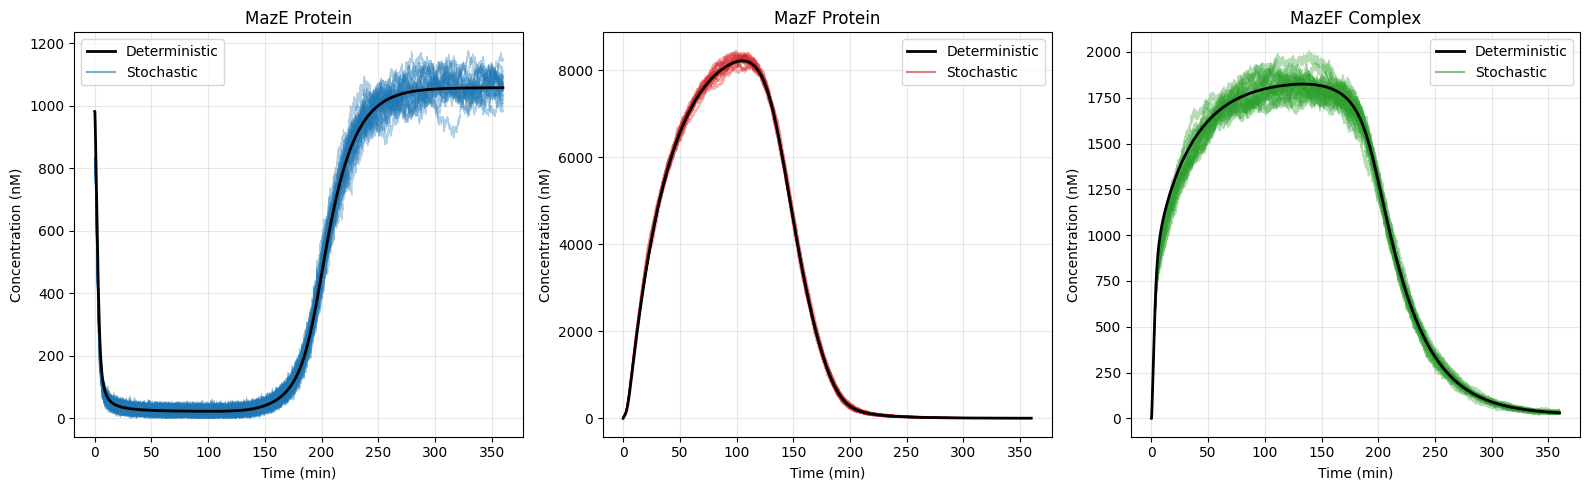

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
k_syn_mazE = 28.32*2 # in nM/min
gamma_maze = 0.053
k_in = 100 # guessed
k_act = 1e-6 # must be significantly smaller than k_deact (should make sense biologically)
k_deact = 1
gamma_arb = 0.06
k_syn = 45.3
gamma_arac = 0.0415
h = 2
K_half = 40 # guessed
mu_mazf = 12
omega_mazf = 10
gamma_mazf = 0.376
chi_mazf = 0.03
k_bind = 0.01
k_unbind = 1
chi_mazef = 0.03
time = 60*6
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

# Initialize variables
prot_maze = np.zeros(n_step)
prot_maze[0] = 982.69
arabinose = np.zeros(n_step)
arabinose[0] = 1e8
AraC = np.zeros(n_step)
AraC[0] = 40
AraC_active = np.zeros(n_step)
prot_mazf = np.zeros(n_step)
prot_mazef = np.zeros(n_step)


# Run for loop
for i in range(n_step - 1):
  dprot_mazef_dt = k_bind*prot_maze[i]*prot_mazf[i] - k_unbind*prot_mazef[i] - chi_mazef*prot_mazef[i]

  dprot_maze_dt = k_syn_mazE - gamma_maze*prot_maze[i] + k_unbind*prot_mazef[i] - k_bind*prot_maze[i]*prot_mazf[i]

  darb_dt = k_in - k_act*arabinose[i]*AraC[i] - gamma_arb*arabinose[i] + k_deact*AraC_active[i]
  dAraC_dt = k_syn - gamma_arac*AraC[i] - k_act*arabinose[i]*AraC[i] + k_deact*AraC_active[i]
  dAraC_active_dt = k_act*arabinose[i]*AraC[i] - k_deact*AraC_active[i] - gamma_arac*AraC_active[i]
  dprot_mazf_dt = (omega_mazf*mu_mazf/gamma_mazf)*(AraC_active[i]**h/(K_half**h + AraC_active[i]**h)) - chi_mazf*prot_mazf[i] - k_bind*prot_maze[i]*prot_mazf[i] + k_unbind*prot_mazef[i]

  prot_maze[i+1] = prot_maze[i] + dprot_maze_dt*delta_t
# Update variables, ensuring concentrations do not drop below zero
  arabinose[i+1] =  arabinose[i] + darb_dt*delta_t
  AraC[i+1] = AraC[i] + dAraC_dt*delta_t
  AraC_active[i+1] =  AraC_active[i] + dAraC_active_dt*delta_t
  prot_mazf[i+1] = prot_mazf[i] + dprot_mazf_dt*delta_t
  prot_mazef[i+1] = prot_mazef[i] + dprot_mazef_dt*delta_t

  conv = 0.6   # molecules per nM (converts nM to molecule counts)

def gillespie(maze_prot=830.29, mazf_prot=0, mazef_prot=0, arabinose0=1e8, AraC0=40,
              AraC_active0=0, max_step=500000*5, tau=0.01, tau_min=1e-4, t_stop=time,
              det_arac_active_series=None):
  t = 0
  # Convert initial concentrations (nM) to molecule counts
  prot_maze = round(maze_prot*conv)
  prot_mazf = round(mazf_prot*conv)
  prot_mazef = round(mazef_prot*conv)
  arabinose = arabinose0
  AraC = AraC0
  AraC_active = AraC_active0 # This is the stochastic AraC_active scalar

  t_vals          = [t]
  prot_maze_vals  = [prot_maze]
  prot_mazf_vals  = [prot_mazf]
  prot_mazef_vals = [prot_mazef]

  for step in range(max_step):
      # Use the deterministic AraC_active series (still in nM) for the Hill function calculation
      aca  = np.interp(t, time_vec, det_arac_active_series)
      hill = aca**h / (K_half**h + aca**h)

      a1  = k_syn_mazE * conv                            # MazE synthesis
      a2  = gamma_maze * prot_maze                       # MazE protein decay
      a3  = (omega_mazf*mu_mazf/gamma_mazf) * hill * conv  # MazF synthesis
      a4  = chi_mazf   * prot_mazf                       # MazF protein decay
      a5  = (k_bind/conv) * prot_maze * prot_mazf        # binding -> complex
      a6  = k_unbind   * prot_mazef                      # unbinding
      a7  = chi_mazef  * prot_mazef                      # complex decay

      a  = [a1, a2, a3, a4, a5, a6, a7]
      a0 = np.sum(a)
      if a0 == 0:
        break

      # Try a leap of size tau_try; shrink and resample if it drives a species negative
      tau_try = tau
      while True:
        # draw firings for every channel at once
        k = [np.random.poisson(ai * tau_try) for ai in a]

        # tentative changes, applied per-branch below
        d_prot_maze  = k[0] - k[1] - k[4] + k[5]
        d_prot_mazf  = k[2] - k[3] - k[4] + k[5]
        d_prot_mazef = k[4] - k[5] - k[6]

        if (prot_maze  + d_prot_maze  >= 0 and
            prot_mazf  + d_prot_mazf  >= 0 and
            prot_mazef + d_prot_mazef >= 0):
          break
        tau_try *= 0.5
        if tau_try < tau_min:
          break   # give up shrinking; clamp after applying

      t += tau_try
      if t > t_stop:
        break
      t_vals.append(t)

      # ---- apply firings through the if-elif ladder ----
      # each branch now fires k[idx] times instead of once
      # (all branches run every step, since multiple channels fire per leap)
      for idx in range(len(a)):
        if idx == 0:      # a1: MazE synthesis
          prot_maze  += k[0]
        elif idx == 1:    # a2: MazE protein decay
          prot_maze  -= k[1]
        elif idx == 2:    # a3: MazF synthesis
          prot_mazf  += k[2]
        elif idx == 3:    # a4: MazF protein decay
          prot_mazf  -= k[3]
        elif idx == 4:    # a5: binding -> complex
          prot_maze  -= k[4]
          prot_mazf  -= k[4]
          prot_mazef += k[4]
        elif idx == 5:    # a6: unbinding
          prot_mazef -= k[5]
          prot_maze  += k[5]
          prot_mazf  += k[5]
        elif idx == 6:    # a7: complex decay
          prot_mazef -= k[6]

      prot_maze  = max(prot_maze, 0)
      prot_mazf  = max(prot_mazf, 0)
      prot_mazef = max(prot_mazef, 0)

      t_vals; # (keep your appends below)
      prot_maze_vals.append(prot_maze)
      prot_mazf_vals.append(prot_mazf)
      prot_mazef_vals.append(prot_mazef)

  return t_vals, prot_maze_vals, prot_mazf_vals, prot_mazef_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20
fig, (ax_maze, ax_mazf, ax_mazef) = plt.subplots(1, 3, figsize=(16, 5))

for i in range(runs):
  t_vals, maze_vals, mazf_vals, mazef_vals = gillespie(det_arac_active_series=AraC_active, tau=0.01, tau_min=1e-4)

  # Convert molecule counts back to nM
  maze_nM  = np.array(maze_vals)  / conv
  mazf_nM  = np.array(mazf_vals)  / conv
  mazef_nM = np.array(mazef_vals) / conv

  ax_maze.plot(t_vals,  maze_nM,  color='tab:blue',   alpha=0.35, lw=0.8)
  ax_mazf.plot(t_vals,  mazf_nM,  color='tab:red',    alpha=0.35, lw=0.8)
  ax_mazef.plot(t_vals, mazef_nM, color='tab:green',  alpha=0.35, lw=0.8)


# Deterministic curves on top (bold black), converted from nM to molecules
ax_maze.plot(time_vec,  prot_maze,  'k', lw=2, label='Deterministic')
ax_mazf.plot(time_vec,  prot_mazf,  'k', lw=2, label='Deterministic')
ax_mazef.plot(time_vec, prot_mazef, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
ax_maze.plot([],  [], color='tab:blue',  alpha=0.6, label='Stochastic')
ax_mazf.plot([],  [], color='tab:red',   alpha=0.6, label='Stochastic')
ax_mazef.plot([], [], color='tab:green', alpha=0.6, label='Stochastic')

ax_maze.set_title('MazE Protein')
ax_mazf.set_title('MazF Protein')
ax_mazef.set_title('MazEF Complex')

for ax in (ax_maze, ax_mazf, ax_mazef):
  ax.set_xlabel('Time (min)')
  ax.set_ylabel('Concentration (nM)')
  ax.grid(alpha = 0.3)
  ax.legend()

plt.tight_layout()
plt.show()
plt.show()

Final mazE concentration: 3711.34 nM
Final mazF concentration: 3.55 nM


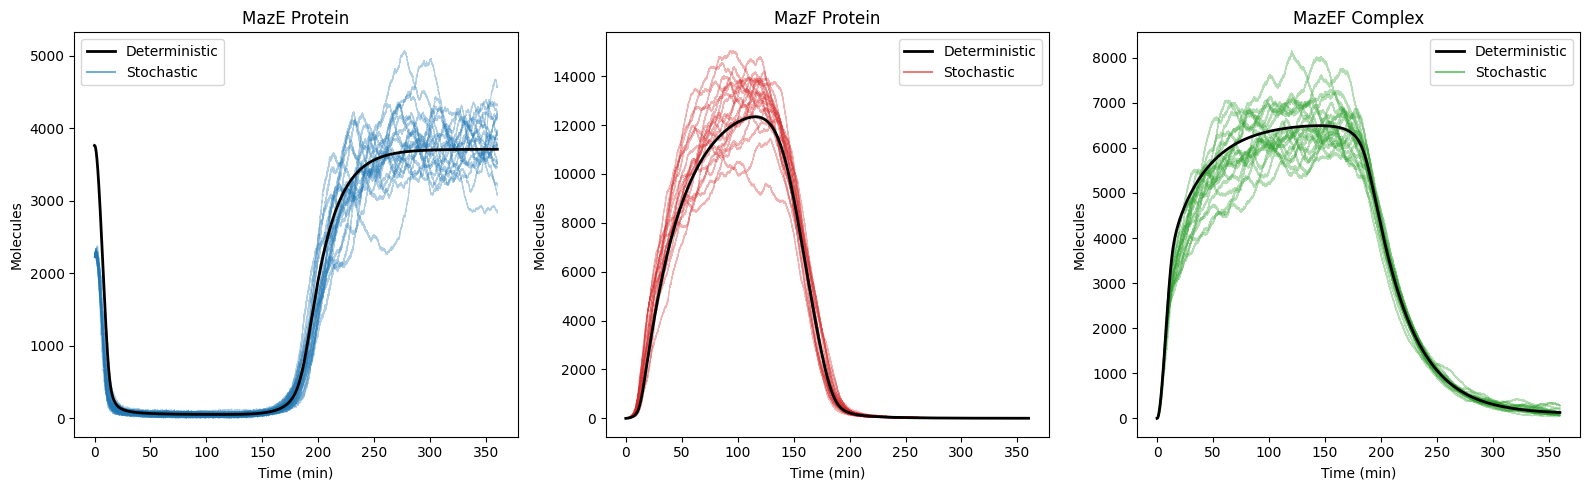

In [ ]:
# ----------------- Older plots -------------------------

import numpy as np
import matplotlib.pyplot as plt

# Define parameters
mu_maze = 4.05
omega_maze = 10
gamma_maze = 0.203
chi_maze = 0.053
k_in = 100 # guessed
k_act = 1e-6 # must be significantly smaller than k_deact (should make sense biologically)
k_deact = 1
gamma_arb = 0.06
k_syn = 45.3
gamma_arac = 0.0415
h = 2
K_half = 25 # guessed
mu_mazf = 12
omega_mazf = 10
gamma_mazf = 0.203
chi_mazf = 0.03
k_bind = 0.01
k_unbind = 1
chi_mazef = 0.03

time = 60*6
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

# Initialize variables
mrna_maze = np.zeros(n_step)
mrna_maze[0] = mu_maze/gamma_maze
prot_maze = np.zeros(n_step)
prot_maze[0] = 3763.92
arabinose = np.zeros(n_step)
arabinose[0] = 1e8
AraC = np.zeros(n_step)
AraC[0] = 40
AraC_active = np.zeros(n_step)
mrna_mazf = np.zeros(n_step)
prot_mazf = np.zeros(n_step)
prot_mazef = np.zeros(n_step)

# Run for loop
for i in range(n_step - 1):
  dprot_mazef_dt = k_bind*prot_maze[i]*prot_mazf[i] - k_unbind*prot_mazef[i] - chi_mazef*prot_mazef[i]

  dmrna_maze_dt = mu_maze - gamma_maze*mrna_maze[i]
  dprot_maze_dt = omega_maze*mrna_maze[i] - chi_maze*prot_maze[i] + k_unbind*prot_mazef[i] - k_bind*prot_maze[i]*prot_mazf[i]

  darb_dt = k_in - k_act*arabinose[i]*AraC[i] - gamma_arb*arabinose[i] + k_deact*AraC_active[i]
  dAraC_dt = k_syn - gamma_arac*AraC[i] - k_act*arabinose[i]*AraC[i] + k_deact*AraC_active[i]
  dAraC_active_dt = k_act*arabinose[i]*AraC[i] - k_deact*AraC_active[i] - gamma_arac*AraC_active[i]
  dmrna_mazf_dt = mu_mazf*(AraC_active[i]**h/(K_half**h + AraC_active[i]**h)) - gamma_mazf*mrna_mazf[i]
  dprot_mazf_dt = omega_mazf*mrna_mazf[i] - chi_mazf*prot_mazf[i] - k_bind*prot_maze[i]*prot_mazf[i] + k_unbind*prot_mazef[i]


  mrna_maze[i+1] = mrna_maze[i] + dmrna_maze_dt*delta_t
  prot_maze[i+1] = prot_maze[i] + dprot_maze_dt*delta_t
# Update variables, ensuring concentrations do not drop below zero
  arabinose[i+1] =  arabinose[i] + darb_dt*delta_t
  AraC[i+1] = AraC[i] + dAraC_dt*delta_t
  AraC_active[i+1] =  AraC_active[i] + dAraC_active_dt*delta_t
  mrna_mazf[i+1] =  mrna_mazf[i] + dmrna_mazf_dt*delta_t
  prot_mazf[i+1] = prot_mazf[i] + dprot_mazf_dt*delta_t
  prot_mazef[i+1] = prot_mazef[i] + dprot_mazef_dt*delta_t

print(f"Final mazE concentration: {np.round(prot_maze[n_step-1],2)} nM")
print(f"Final mazF concentration: {np.round(prot_mazf[n_step-1],2)} nM")

mu_maze = 4.05
omega_maze = 10
gamma_maze = 0.203
chi_maze = 0.053
k_in = 100 # guessed
k_act = 0.0167 # must be significantly smaller than k_deact (should make sense biologically)
k_deact = 1
gamma_arb = 0.06
k_syn = 45.3
gamma_arac = 0.0415
h = 2
K_half = 25 # guessed
mu_mazf = 12
omega_mazf = 10
gamma_mazf = 0.203
chi_mazf = 0.03
k_bind = 0.01
k_unbind = 1
chi_mazef = 0.03

def gillespie(maze_rna=mu_maze/gamma_maze, maze_prot=2228.14, mazf_mrna=0,
              mazf_prot=0, mazef_prot=0, arabinose0=6000, AraC0=40, AraC_active0=0,
              max_step=500000*5, tau=0.01, tau_min=1e-4, t_stop=time, det_arac_active_series=None):

  t = 0
  mrna_maze = maze_rna
  prot_maze = maze_prot
  mrna_mazf = mazf_mrna
  prot_mazf = mazf_prot # Corrected from prot_mazf = prot_mazf
  prot_mazef = mazef_prot
  arabinose = arabinose0
  AraC = AraC0
  AraC_active = AraC_active0 # This is the stochastic AraC_active scalar

  t_vals          = [t]
  mrna_maze_vals  = [mrna_maze]
  prot_maze_vals  = [prot_maze]
  mrna_mazf_vals  = [mrna_mazf]
  prot_mazf_vals  = [prot_mazf]
  prot_mazef_vals = [prot_mazef]

  for step in range(max_step):
      # Use the deterministic AraC_active series for the Hill function calculation
      aca  = np.interp(t, time_vec, det_arac_active_series)
      hill = aca**h / (K_half**h + aca**h)

      a1  = mu_maze                        # MazE transcription
      a2  = gamma_maze * mrna_maze         # MazE mRNA decay
      a3  = omega_maze * mrna_maze         # MazE translation
      a4  = chi_maze   * prot_maze         # MazE protein decay
      a5  = mu_mazf    * hill              # MazF transcription
      a6  = gamma_mazf * mrna_mazf         # MazF mRNA decay
      a7  = omega_mazf * mrna_mazf         # MazF translation
      a8  = chi_mazf   * prot_mazf         # MazF protein decay
      a9  = k_bind     * prot_maze * prot_mazf  # binding -> complex
      a10 = k_unbind   * prot_mazef        # unbinding
      a11 = chi_mazef  * prot_mazef        # complex decay

      a  = [a1, a2, a3, a4, a5, a6, a7, a8, a9, a10, a11]
      a0 = np.sum(a)
      if a0 == 0:
        break

      # Try a leap of size tau_try; shrink and resample if it drives a species negative
      tau_try = tau
      while True:
        # draw firings for every channel at once
        k = [np.random.poisson(ai * tau_try) for ai in a]

        # tentative changes, applied per-branch below
        d_mrna_maze  = k[0] - k[1]
        d_prot_maze  = k[2] - k[3] - k[8] + k[9]
        d_mrna_mazf  = k[4] - k[5]
        d_prot_mazf  = k[6] - k[7] - k[8] + k[9]
        d_prot_mazef = k[8] - k[9] - k[10]

        if (mrna_maze  + d_mrna_maze  >= 0 and
            prot_maze  + d_prot_maze  >= 0 and
            mrna_mazf  + d_mrna_mazf  >= 0 and
            prot_mazf  + d_prot_mazf  >= 0 and
            prot_mazef + d_prot_mazef >= 0):
          break
        tau_try *= 0.5
        if tau_try < tau_min:
          break   # give up shrinking; clamp after applying

      t += tau_try
      if t > t_stop:
        break
      t_vals.append(t)

      # ---- apply firings through the if-elif ladder ----
      # each branch now fires k[idx] times instead of once
      # (all branches run every step, since multiple channels fire per leap)
      for idx in range(len(a)):
        if idx == 0:      # a1: MazE transcription
          mrna_maze  += k[0]
        elif idx == 1:    # a2: MazE mRNA decay
          mrna_maze  -= k[1]
        elif idx == 2:    # a3: MazE translation
          prot_maze  += k[2]
        elif idx == 3:    # a4: MazE protein decay
          prot_maze  -= k[3]
        elif idx == 4:    # a5: MazF transcription
          mrna_mazf  += k[4]
        elif idx == 5:    # a6: MazF mRNA decay
          mrna_mazf  -= k[5]
        elif idx == 6:    # a7: MazF translation
          prot_mazf  += k[6]
        elif idx == 7:    # a8: MazF protein decay
          prot_mazf  -= k[7]
        elif idx == 8:    # a9: binding -> complex
          prot_maze  -= k[8]
          prot_mazf  -= k[8]
          prot_mazef += k[8]
        elif idx == 9:    # a10: unbinding
          prot_mazef -= k[9]
          prot_maze  += k[9]
          prot_mazf  += k[9]
        elif idx == 10:   # a11: complex decay
          prot_mazef -= k[10]

      mrna_maze  = max(mrna_maze, 0)
      prot_maze  = max(prot_maze, 0)
      mrna_mazf  = max(mrna_mazf, 0)
      prot_mazf  = max(prot_mazf, 0)
      prot_mazef = max(prot_mazef, 0)

      t_vals; # (keep your appends below)
      mrna_maze_vals.append(mrna_maze)
      prot_maze_vals.append(prot_maze)
      mrna_mazf_vals.append(mrna_mazf)
      prot_mazf_vals.append(prot_mazf)
      prot_mazef_vals.append(prot_mazef)

  return t_vals, mrna_maze_vals, prot_maze_vals, mrna_mazf_vals, prot_mazf_vals, prot_mazef_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20
fig, (ax_maze, ax_mazf, ax_mazef) = plt.subplots(1, 3, figsize=(16, 5))

for i in range(runs):
  # Pass the globally defined 'AraC_active' array (from the deterministic part)
  # to the gillespie function for interpolation.
  t_vals, _, maze_vals, _, mazf_vals, mazef_vals = gillespie(det_arac_active_series=AraC_active, tau=0.01, tau_min=1e-4)
  ax_maze.plot(t_vals,  maze_vals,  color='tab:blue',   alpha=0.35, lw=0.8)
  ax_mazf.plot(t_vals,  mazf_vals,  color='tab:red',    alpha=0.35, lw=0.8)
  ax_mazef.plot(t_vals, mazef_vals, color='tab:green',  alpha=0.35, lw=0.8)

# Deterministic curves on top (bold black)
ax_maze.plot(time_vec,  prot_maze,  'k', lw=2, label='Deterministic')
ax_mazf.plot(time_vec,  prot_mazf,  'k', lw=2, label='Deterministic')
ax_mazef.plot(time_vec, prot_mazef, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
ax_maze.plot([],  [], color='tab:blue',  alpha=0.6, label='Stochastic')
ax_mazf.plot([],  [], color='tab:red',   alpha=0.6, label='Stochastic')
ax_mazef.plot([], [], color='tab:green', alpha=0.6, label='Stochastic')

ax_maze.set_title('MazE Protein')
ax_mazf.set_title('MazF Protein')
ax_mazef.set_title('MazEF Complex')

for ax in (ax_maze, ax_mazf, ax_mazef):
  ax.set_xlabel('Time (min)')
  ax.set_ylabel('Molecules')
  ax.legend()

plt.tight_layout()
plt.show()